<a href="https://colab.research.google.com/github/YuttapongR/Capstone_Project_Data_Mining-/blob/main/%E0%B8%AA%E0%B8%A0%E0%B8%B2%E0%B8%9E%E0%B8%AD%E0%B8%B2%E0%B8%81%E0%B8%B2%E0%B8%A8%E0%B9%83%E0%B8%99%E0%B8%AD%E0%B8%B4%E0%B8%99%E0%B9%80%E0%B8%94%E0%B8%B5%E0%B8%A2%E0%B9%81%E0%B8%A2%E0%B9%88%E0%B9%81%E0%B8%84%E0%B9%88%E0%B9%84%E0%B8%AB%E0%B8%99.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

### ตารางสรุปประเภทข้อมูล (Data Types)

| คอลัมน์ | ประเภท | เหตุผล |
| :--- | :--- | :--- |
| **City** | Nominal | ชื่อเมือง ไม่มีลำดับ |
| **Date** | ข้อมูลวันที่ (Interval/Time) | ไม่ใช่ Nominal และไม่ใช่ Ordinal ปกติใช้แตกเป็นปี/เดือน |
| **AQI_Bucket** | Ordinal | Good &rarr; Satisfactory &rarr; Moderate &rarr; Poor &rarr; Very Poor &rarr; Severe เรียงลำดับได้ |
| **PM2.5, PM10, NO, NO2, NOx, NH3, CO, SO2, O3, Benzene, Toluene, Xylene** | ตัวเลข (Ratio) | ค่าความเข้มข้นของมลพิษ ไม่ใช่หมวดหมู่ มีศูนย์แท้ |
| **AQI** | ตัวเลข (Ratio) | ค่าดัชนีเป็นตัวเลขวัดระดับความเข้มข้น มีศูนย์แท้ |

In [ ]:
import kagglehub
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report

warnings.filterwarnings('ignore')

# Download latest version
path = kagglehub.dataset_download("rohanrao/air-quality-data-in-india")
print("Path to dataset files:", path)

Using Colab cache for faster access to the 'air-quality-data-in-india' dataset.
Path to dataset files: /kaggle/input/air-quality-data-in-india


In [ ]:
import os
city_day_file = os.path.join(path, 'city_day.csv')

if os.path.exists(city_day_file):
    df = pd.read_csv(city_day_file)
    print(f"ขนาดของข้อมูล city_day.csv: {df.shape}")
    display(df.head())
else:
    print("ไม่พบไฟล์ city_day.csv")

ขนาดของข้อมูล city_day.csv: (29531, 16)


,City,Date,PM2.5,PM10,NO,NO2,NOx,NH3,CO,SO2,O3,Benzene,Toluene,Xylene,AQI,AQI_Bucket
0,Ahmedabad,2015-01-01,NaN,NaN,0.92,18.22,17.15,NaN,0.92,27.64,133.36,0.00,0.02,0.00,NaN,NaN
1,Ahmedabad,2015-01-02,NaN,NaN,0.97,15.69,16.46,NaN,0.97,24.55,34.06,3.68,5.50,3.77,NaN,NaN
2,Ahmedabad,2015-01-03,NaN,NaN,17.40,19.30,29.70,NaN,17.40,29.07,30.70,6.80,16.40,2.25,NaN,NaN
3,Ahmedabad,2015-01-04,NaN,NaN,1.70,18.48,17.97,NaN,1.70,18.59,36.08,4.43,10.14,1.00,NaN,NaN
4,Ahmedabad,2015-01-05,NaN,NaN,22.10,21.42,37.76,NaN,22.10,39.33,39.31,7.01,18.89,2.78,NaN,NaN


In [ ]:
df.shape

(29531, 16)

PM2.5	ฝุ่นละอองขนาดไม่เกิน 2.5 ไมครอน

PM10	ฝุ่นละอองขนาดไม่เกิน 10 ไมครอน

NO	ไนตริกออกไซด์

NO2	ไนโตรเจนไดออกไซด์

NOx	ก๊าซไนโตรเจนออกไซด์รวม

NH3	แอมโมเนีย

CO	คาร์บอนมอนอกไซด์

SO2	ซัลเฟอร์ไดออกไซด์

O3	โอโซนระดับพื้นดิน

Benzene	เบนซีน

Toluene	โทลูอีน

Xylene	ไซลีน

In [ ]:
display(df.isnull().sum())

,0
City,0
Date,0
PM2.5,4598
PM10,11140
NO,3582
NO2,3585
NOx,4185
NH3,10328
CO,2059
SO2,3854


In [ ]:
num_cols = ["PM2.5", "PM10", "NO", "NO2", "NOx", "NH3", "CO", "SO2", "O3", "Benzene", "Toluene", "Xylene", "AQI"]

median_num = df[num_cols].median()

df[num_cols] = df[num_cols].fillna(median_num)

display(df.isnull().sum())

,0
City,0
Date,0
PM2.5,0
PM10,0
NO,0
NO2,0
NOx,0
NH3,0
CO,0
SO2,0


In [ ]:
df.describe()

,PM2.5,PM10,NO,NO2,NOx,NH3,CO,SO2,O3,Benzene,Toluene,Xylene,AQI
count,29531.000000,29531.000000,29531.000000,29531.000000,29531.000000,29531.000000,29531.000000,29531.000000,29531.000000,29531.000000,29531.000000,29531.000000,29531.000000
mean,64.510857,109.659366,16.642601,27.726576,31.063568,20.813789,2.153872,13.830897,33.994121,2.859874,7.140485,1.788420,158.781552
std,59.807551,72.324020,21.506064,23.050531,29.477748,21.028862,6.724660,17.005647,20.202304,14.252822,17.224737,4.062039,130.272413
min,0.040000,0.010000,0.020000,0.010000,0.000000,0.010000,0.000000,0.010000,0.010000,0.000000,0.000000,0.000000,13.000000
25%,32.150000,79.315000,6.210000,12.980000,14.670000,12.040000,0.540000,6.090000,20.740000,0.240000,1.280000,0.980000,88.000000
50%,48.570000,95.680000,9.890000,21.690000,23.520000,15.850000,0.890000,9.160000,30.840000,1.070000,2.970000,0.980000,118.000000
75%,72.450000,111.880000,17.570000,34.665000,36.015000,21.755000,1.380000,13.810000,42.730000,2.420000,6.020000,0.980000,179.000000
max,949.990000,1000.000000,390.680000,362.210000,467.630000,352.890000,175.810000,193.860000,257.730000,455.030000,454.850000,170.370000,2049.000000


In [ ]:
# 1. ลบแถวที่เป็นค่าว่างในคอลัมน์กลุ่มเป้าหมาย (AQI_Bucket) ออกก่อน
df_clean = df.dropna(subset=['AQI_Bucket'])

# 2. ระบุคอลัมน์ตัวเลขหลักที่ต้องการกำจัด Outliers
features_to_clean = ["PM2.5", "PM10", "NO", "NO2", "NOx", "NH3", "CO", "SO2", "O3"]

# เก็บจำนวนแถวก่อนเริ่มกำจัด Outliers
original_row_count = len(df_clean)
print(f"จำนวนข้อมูลสะอาดเริ่มต้น: {original_row_count} แถว")

# สร้าง DataFrame ใหม่ที่กรอง Outliers ออก
df_no_outliers = df_clean.copy()

for col in features_to_clean:
    Q1_col = df_no_outliers[col].quantile(0.25)
    Q3_col = df_no_outliers[col].quantile(0.75)
    IQR_col = Q3_col - Q1_col

    # กำหนดเกณฑ์ขอบเขตบนและล่าง (1.5 เท่าของ IQR)
    lower_bound = Q1_col - 1.5 * IQR_col
    upper_bound = Q3_col + 1.5 * IQR_col

    # กรองเอาเฉพาะข้อมูลที่อยู่ในขอบเขตปกติ
    df_no_outliers = df_no_outliers[(df_no_outliers[col] >= lower_bound) & (df_no_outliers[col] <= upper_bound)]

# เก็บจำนวนแถวหลังจากกรองแล้ว
cleaned_row_count = len(df_no_outliers)
removed_rows = original_row_count - cleaned_row_count

print(f"จำนวนข้อมูลหลังกำจัด Outliers: {cleaned_row_count} แถว")
print(f"จำนวนข้อมูลที่ถูกกรองออก (Outliers): {removed_rows} แถว (คิดเป็น {(removed_rows/original_row_count)*100:.2f}%)")

จำนวนข้อมูลสะอาดเริ่มต้น: 24850 แถว
จำนวนข้อมูลหลังกำจัด Outliers: 13507 แถว
จำนวนข้อมูลที่ถูกกรองออก (Outliers): 11343 แถว (คิดเป็น 45.65%)


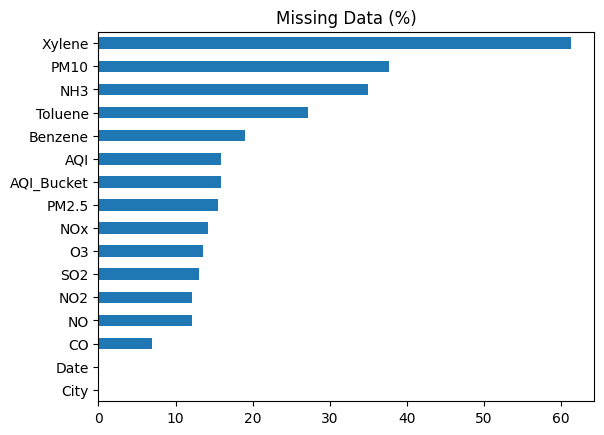

In [ ]:
raw = pd.read_csv(city_day_file, parse_dates=['Date'])
a = raw.dropna(subset=['AQI'])

(raw.isnull().mean() * 100).sort_values().plot.barh(title='Missing Data (%)')
plt.show()

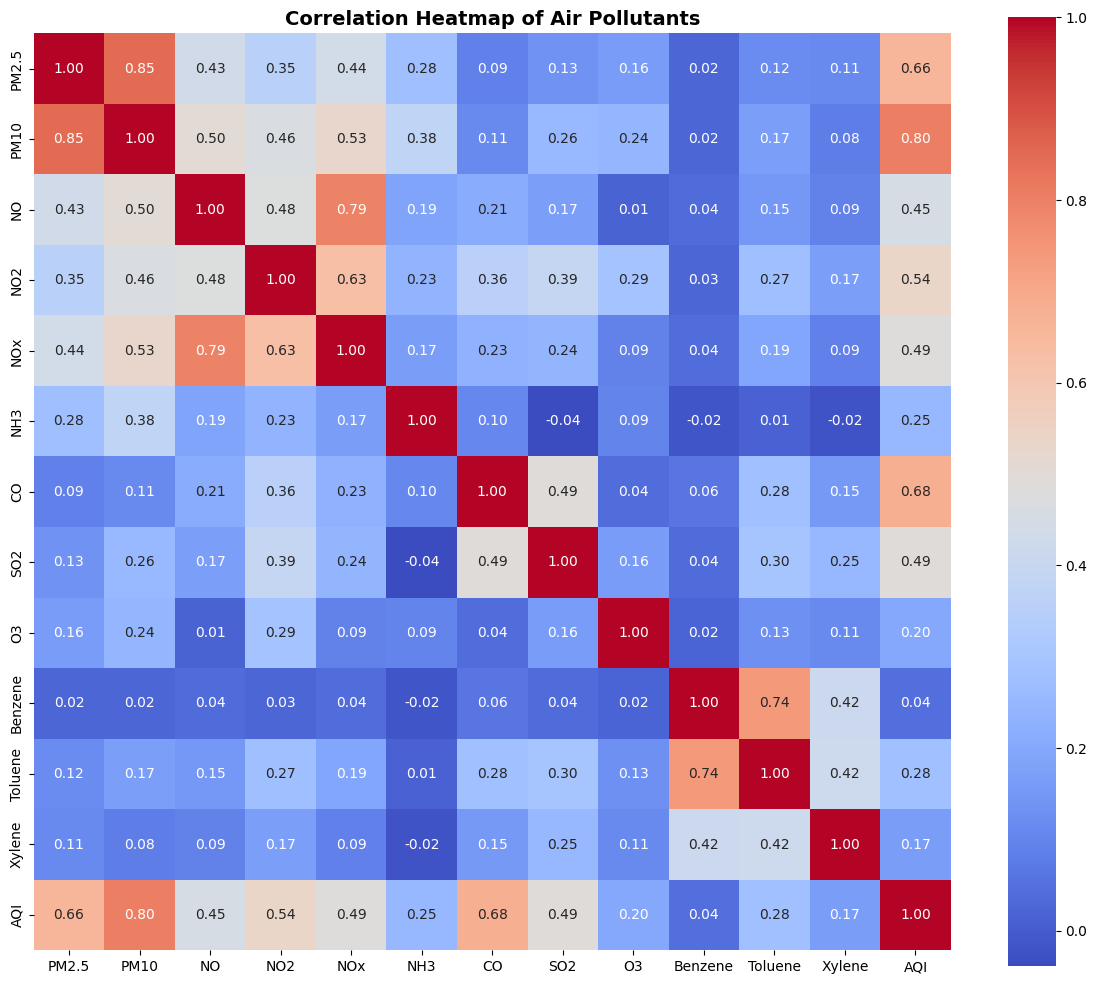

In [ ]:
plt.figure(figsize=(12, 10))
sns.heatmap(raw[num_cols].corr(), annot=True, fmt='.2f', cmap='coolwarm', square=True)
plt.title('Correlation Heatmap of Air Pollutants', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

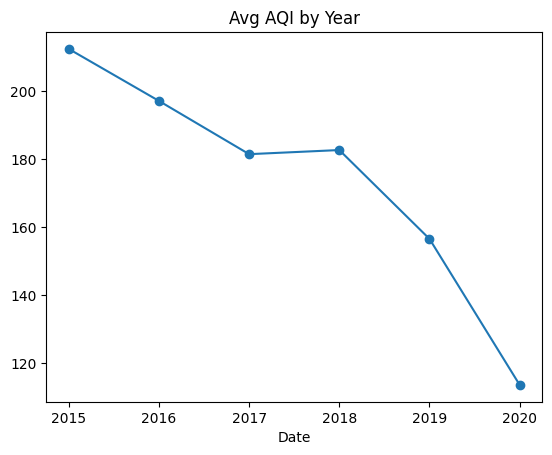

In [ ]:
# โหลดข้อมูลดิบใหม่เพื่อใช้ในกระบวนการ EDA วิเคราะห์แนวโน้ม
a.groupby(a['Date'].dt.year)['AQI'].mean().plot(marker='o', title='Avg AQI by Year')
plt.show()

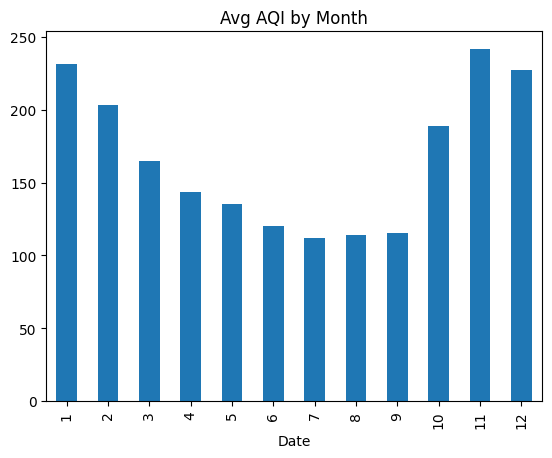

In [ ]:
a.groupby(a['Date'].dt.month)['AQI'].mean().plot(kind='bar', title='Avg AQI by Month')
plt.show()

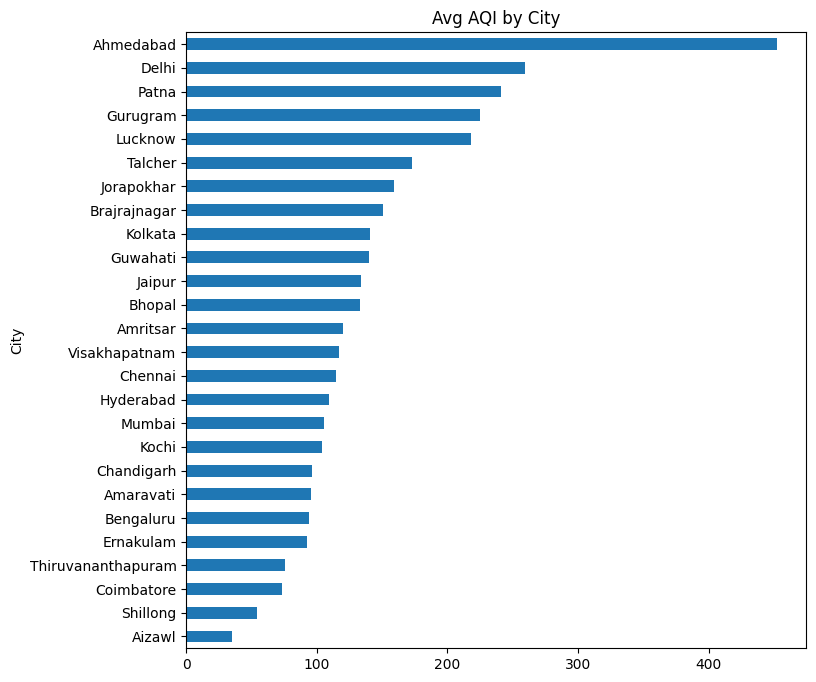

In [ ]:
a.groupby('City')['AQI'].mean().sort_values().plot.barh(figsize=(8, 8), title='Avg AQI by City')
plt.show()

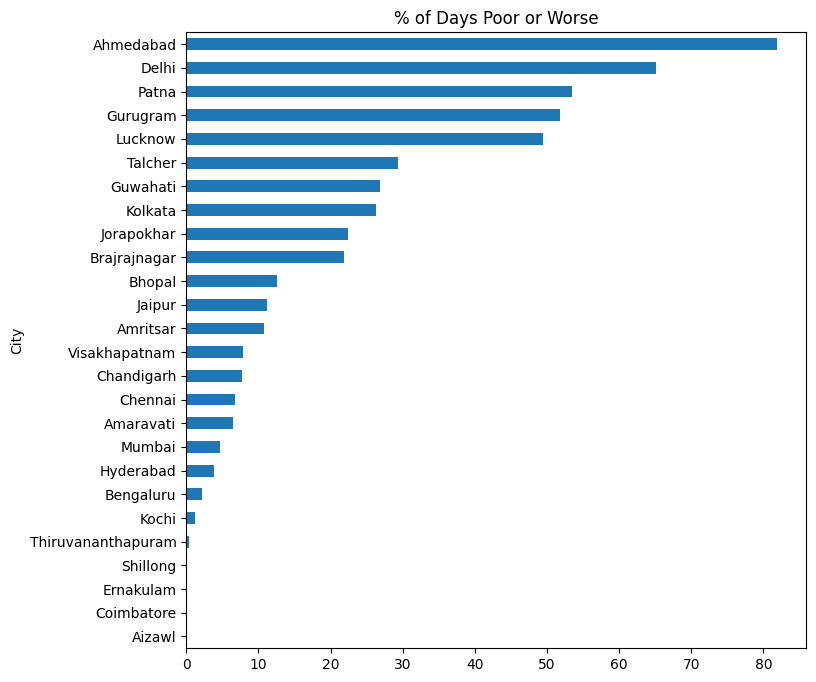

In [ ]:
bad = a['AQI_Bucket'].isin(['Poor', 'Very Poor', 'Severe'])
bad.groupby(a['City']).mean().mul(100).sort_values().plot.barh(figsize=(8, 8), title='% of Days Poor or Worse')
plt.show()

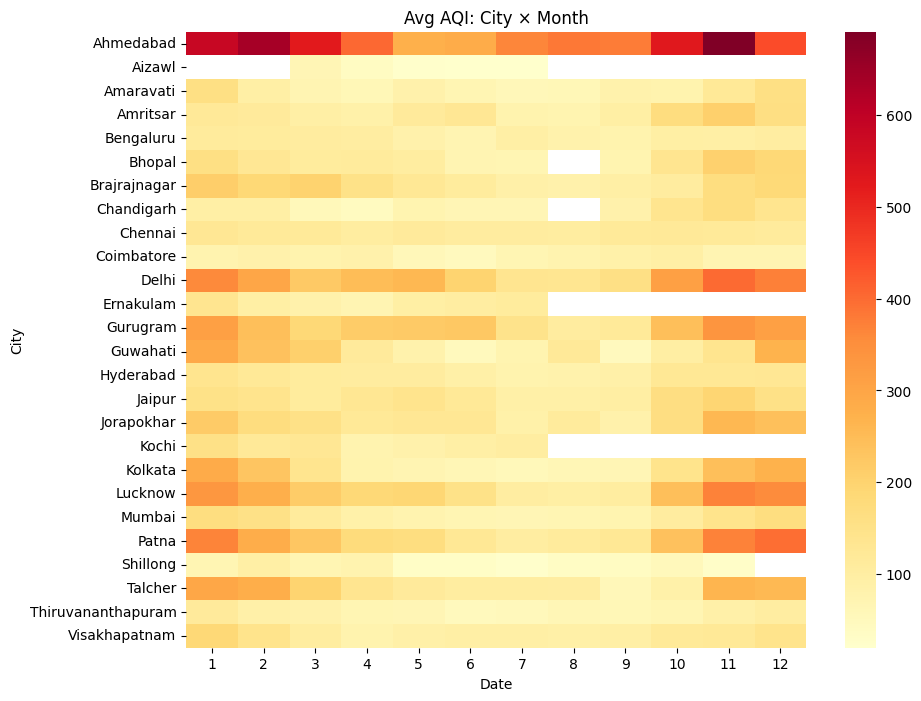

In [ ]:
plt.figure(figsize=(10, 8))
sns.heatmap(a.pivot_table(index='City', columns=a['Date'].dt.month, values='AQI'), cmap='YlOrRd')
plt.title('Avg AQI: City × Month')
plt.show()

== Decision Tree Classification Report ==
              precision    recall  f1-score   support

        Good       0.60      0.57      0.58       268
    Moderate       0.79      0.78      0.78      1766
        Poor       0.68      0.59      0.63       556
Satisfactory       0.76      0.82      0.79      1645
      Severe       0.85      0.80      0.82       268
   Very Poor       0.79      0.74      0.76       467

    accuracy                           0.76      4970
   macro avg       0.74      0.72      0.73      4970
weighted avg       0.76      0.76      0.76      4970

--------------------------------------------------
== Random Forest Classification Report ==
              precision    recall  f1-score   support

        Good       0.97      0.13      0.24       268
    Moderate       0.74      0.86      0.79      1766
        Poor       0.73      0.45      0.56       556
Satisfactory       0.76      0.85      0.81      1645
      Severe       0.86      0.55      0.67       2

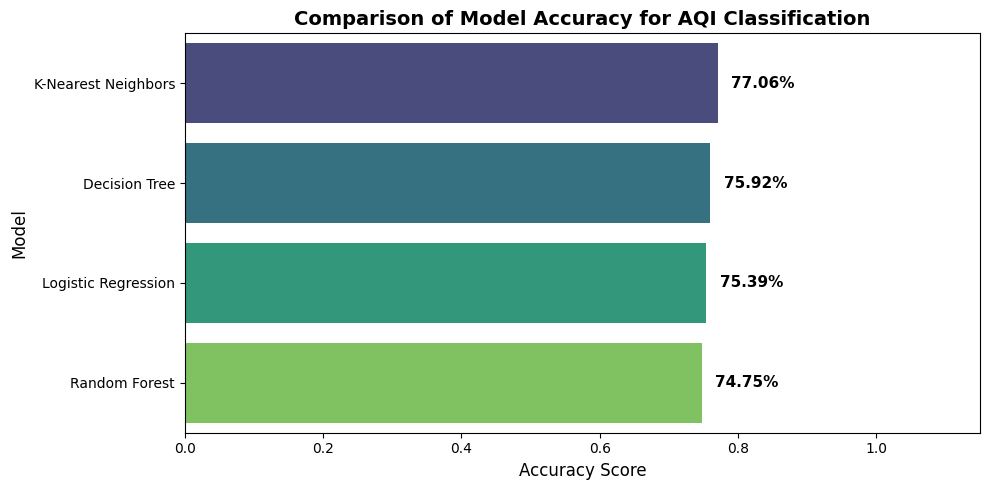

In [ ]:
# เตรียมข้อมูล
df_clean = df.dropna(subset=['AQI_Bucket'])
features = ["PM2.5", "PM10", "NO", "NO2", "NOx", "NH3", "CO", "SO2", "O3", "Benzene", "Toluene", "Xylene"]
X = df_clean[features]
y = df_clean['AQI_Bucket']

# แบ่งข้อมูลชุดสอน (Train) และทดสอบ (Test)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

# นิยามโมเดลทั้งหมดที่ต้องการทดสอบ
models = {
    'Decision Tree': DecisionTreeClassifier(max_depth=5, random_state=42),
    'Random Forest': RandomForestClassifier(n_estimators=50, max_depth=5, random_state=42),
    'K-Nearest Neighbors': Pipeline([
        ('scaler', StandardScaler()),
        ('knn', KNeighborsClassifier(n_neighbors=5))
    ]),
    'Logistic Regression': Pipeline([
        ('scaler', StandardScaler()),
        ('log_reg', LogisticRegression(multi_class='multinomial', solver='lbfgs', max_iter=200, random_state=42))
    ])
}

# ฝึกสอน (Train) และประเมินผลประสิทธิภาพของแต่ละโมเดล
results = {}
for name, clf in models.items():
    clf.fit(X_train, y_train)
    y_pred_model = clf.predict(X_test)
    acc = accuracy_score(y_test, y_pred_model)
    results[name] = acc
    print(f"== {name} Classification Report ==")
    print(classification_report(y_test, y_pred_model))
    print("-" * 50)

# แปลงเป็น DataFrame และพล็อตกราฟสรุปความเหมาะเพื่อนำเสนอ
results_df = pd.DataFrame(list(results.items()), columns=['Model', 'Accuracy']).sort_values(by='Accuracy', ascending=False)

plt.figure(figsize=(10, 5))
ax = sns.barplot(x='Accuracy', y='Model', data=results_df, palette='viridis', hue='Model', legend=False)
plt.xlim(0.0, 1.15)
plt.title('Comparison of Model Accuracy for AQI Classification', fontsize=14, fontweight='bold')
plt.xlabel('Accuracy Score', fontsize=12)
plt.ylabel('Model', fontsize=12)

for index, row in results_df.reset_index(drop=True).iterrows():
    value = row['Accuracy']
    if value > 0.90:
        plt.text(value - 0.02, index, f"{value*100:.2f}%", color='white', fontweight='bold', va='center', ha='right', fontsize=11)
    else:
        plt.text(value + 0.02, index, f"{value*100:.2f}%", color='black', fontweight='bold', va='center', ha='left', fontsize=11)

plt.tight_layout()
plt.show()

In [ ]:
import pandas as pd

# 1. ระบุข้อมูลตัวอย่างที่ต้องการทำนายผลพร้อมคำอธิบายตัวแปร
new_air_data = pd.DataFrame([{
    "PM2.5": 120.5,    # ฝุ่นละอองขนาดเล็กไม่เกิน 2.5 ไมครอน
    "PM10": 180.2,     # ฝุ่นละอองขนาดเล็กไม่เกิน 10 ไมครอน
    "NO": 15.1,        # ก๊าซไนตริกออกไซด์
    "NO2": 35.4,       # ก๊าซไนโตรเจนไดออกไซด์
    "NOx": 28.0,       # ก๊าซกลุ่มไนโตรเจนออกไซด์รวม
    "NH3": 12.5,       # ก๊าซแอมโมเนีย
    "CO": 1.8,         # ก๊าซคาร์บอนมอนอกไซด์
    "SO2": 14.2,       # ก๊าซซัลเฟอร์ไดออกไซด์
    "O3": 65.0,        # ก๊าซโอโซนภาคพื้นดิน
    "Benzene": 2.1,    # สารพิษระเหยง่ายเบนซีน
    "Toluene": 4.5,    # สารพิษระเหยง่ายโทลูอีน
    "Xylene": 0.98,    # สารพิษระเหยง่ายไซลีน
}])

# 2. ค้นหาโมเดลที่ให้ความแม่นยำสูงที่สุดจากการประเมินก่อนหน้าแบบไดนามิก
best_model_name = max(results, key=results.get)
best_model = models[best_model_name]

# 3. ใช้โมเดลที่ดีที่สุดตัวนั้นทำการทำนายผลข้อมูลใหม่
predicted_bucket = best_model.predict(new_air_data)

print(f"⭐ Best Model Selected: {best_model_name} (Accuracy: {results[best_model_name]*100:.2f}%)")
print(f"🔮 ผลลัพธ์การทำนายระดับคุณภาพอากาศ (AQI Bucket): {predicted_bucket[0]}")

⭐ Best Model Selected: K-Nearest Neighbors (Accuracy: 77.06%)
🔮 ผลลัพธ์การทำนายระดับคุณภาพอากาศ (AQI Bucket): Poor


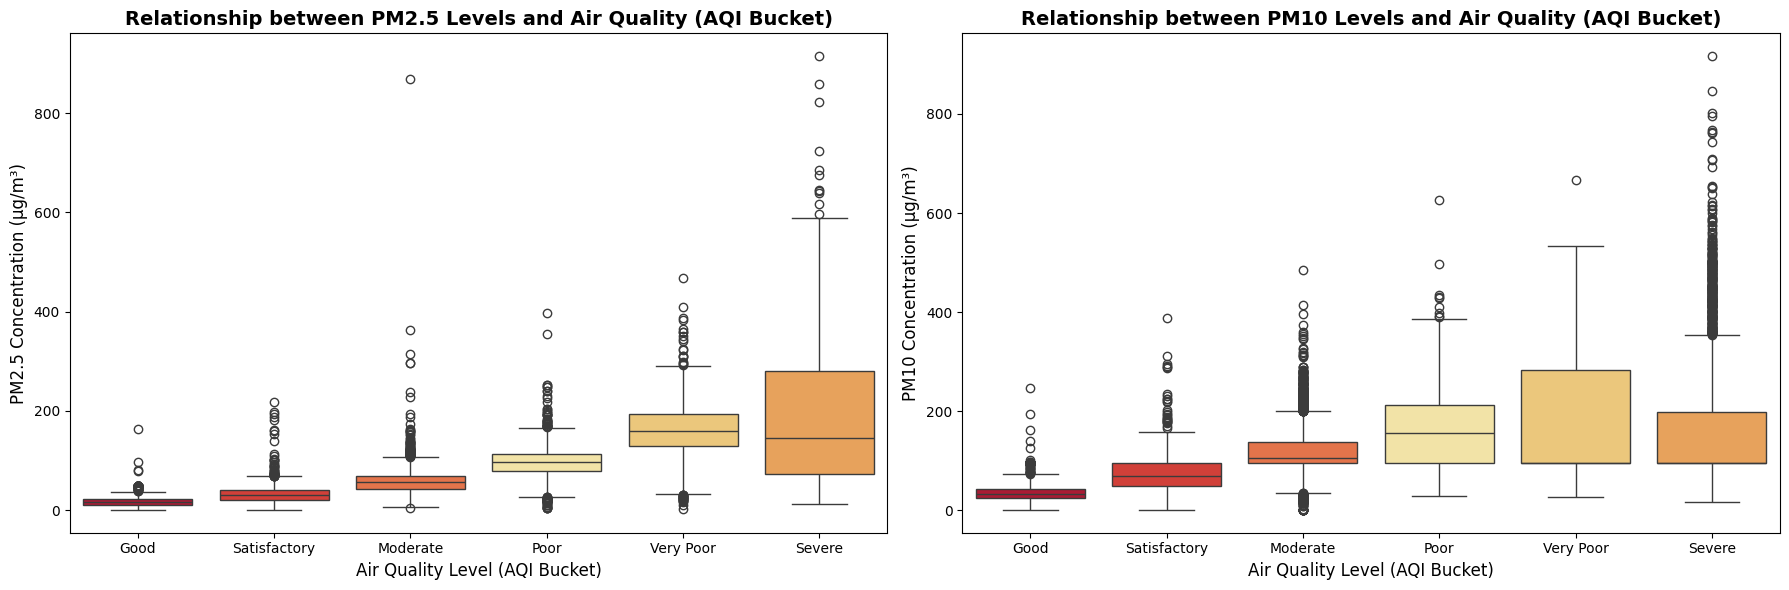

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

# ปิดการแจ้งเตือนเพื่อความสะอาดของ Output
warnings.filterwarnings('ignore', category=UserWarning)
warnings.filterwarnings('ignore', category=FutureWarning)

# กำหนดลำดับของระดับคุณภาพอากาศเพื่อให้กราฟเรียงลำดับอย่างถูกต้อง
bucket_order = ['Good', 'Satisfactory', 'Moderate', 'Poor', 'Very Poor', 'Severe']

# สร้างพื้นที่แสดงกราฟเปรียบเทียบระหว่าง PM2.5 และ PM10
fig, axes = plt.subplots(1, 2, figsize=(18, 6))

# กราฟที่ 1: Boxplot ของ PM2.5 ในแต่ละ AQI Bucket
sns.boxplot(
    x='AQI_Bucket',
    y='PM2.5',
    data=df_clean,
    order=bucket_order,
    ax=axes[0],
    palette='YlOrRd',
    hue='AQI_Bucket',
    legend=False
)
axes[0].set_title('Relationship between PM2.5 Levels and Air Quality (AQI Bucket)', fontsize=14, fontweight='bold')
axes[0].set_xlabel('Air Quality Level (AQI Bucket)', fontsize=12)
axes[0].set_ylabel('PM2.5 Concentration (µg/m³)', fontsize=12)

# กราฟที่ 2: Boxplot ของ PM10 ในแต่ละ AQI Bucket
sns.boxplot(
    x='AQI_Bucket',
    y='PM10',
    data=df_clean,
    order=bucket_order,
    ax=axes[1],
    palette='YlOrRd',
    hue='AQI_Bucket',
    legend=False
)
axes[1].set_title('Relationship between PM10 Levels and Air Quality (AQI Bucket)', fontsize=14, fontweight='bold')
axes[1].set_xlabel('Air Quality Level (AQI Bucket)', fontsize=12)
axes[1].set_ylabel('PM10 Concentration (µg/m³)', fontsize=12)

plt.tight_layout()
plt.show()